# Лабораторная работа 04 — Exploratory Data Analysis
**Основы Data Science**

Разведывательный анализ данных о штатах США, кредитах, ценных бумагах, жилье и задержках рейсов. Данные читаются из локального архива `data-EDA.zip`. Выполните все ячейки сверху вниз, чтобы пересчитать таблицы и графики.

In [1]:
from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import wquantiles
from IPython.display import display
from matplotlib.colors import LogNorm
from scipy.stats import gaussian_kde, trim_mean
from statsmodels import robust

%matplotlib inline
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.family": "DejaVu Sans", "figure.dpi": 110})

BLUE = "#256a9f"
TEAL = "#15796e"
ORANGE = "#a84927"

archive_paths = (
    Path("data-EDA.zip"),
    Path("eda/data-EDA.zip"),
    Path("lab4/eda/data-EDA.zip"),
)
archive_path = next((path for path in archive_paths if path.is_file()), None)
if archive_path is None:
    raise FileNotFoundError("Поместите data-EDA.zip рядом с ноутбуком и запустите его из этой папки.")

def read_csv(archive, filename, **kwargs):
    compression = "gzip" if filename.endswith(".gz") else None
    with archive.open(f"data/{filename}") as source:
        return pd.read_csv(source, compression=compression, **kwargs)

with ZipFile(archive_path) as archive:
    state = read_csv(archive, "state.csv")
    dfw = read_csv(archive, "dfw_airline.csv")
    airline_stats = read_csv(archive, "airline_stats.csv")
    kc_tax = read_csv(archive, "kc_tax.csv.gz", dtype={"ZipCode": "string"})
    lc_loans = read_csv(archive, "lc_loans.csv")
    sp500 = read_csv(archive, "sp500_data.csv.gz", index_col=0, parse_dates=True)
    sectors = read_csv(archive, "sp500_sectors.csv")

datasets = {
    "state": state,
    "dfw_airline": dfw,
    "airline_stats": airline_stats,
    "kc_tax": kc_tax,
    "lc_loans": lc_loans,
    "sp500_data": sp500,
    "sp500_sectors": sectors,
}
sizes = [(name, *frame.shape) for name, frame in datasets.items()]
display(pd.DataFrame(sizes, columns=["Набор", "Строк", "Столбцов"]).set_index("Набор"))

,Строк,Столбцов
Набор,,
state,50,4
dfw_airline,1,5
airline_stats,33468,4
kc_tax,498249,3
lc_loans,450961,2
sp500_data,5647,517
sp500_sectors,517,4


## 1. Структура и типы данных

Единица наблюдения в `state` — штат США. Для каждого столбца проверим тип, число пропусков и число различных наблюдаемых значений.

In [2]:
audit = pd.DataFrame({
    "dtype": state.dtypes.astype(str),
    "missing": state.isna().sum(),
    "nunique": state.nunique(),
})
print(f"Размер data frame: {state.shape[0]} строк × {state.shape[1]} столбца")
display(audit)

Размер data frame: 50 строк × 4 столбца


,dtype,missing,nunique
State,str,0,50
Population,int64,0,50
Murder.Rate,float64,0,34
Abbreviation,str,0,50


### Ответ 1

Таблица содержит 50 штатов и 4 столбца без пропусков. `Population` — целочисленная численность населения, `Murder.Rate` — вещественный уровень убийств на 100 тыс. жителей. У населения 50 уникальных значений, у уровня убийств — 34. `State` и `Abbreviation` — номинальные идентификаторы, по 50 уникальных значений каждый.

У числовых признаков имеют смысл медиана, размах и гистограмма. Для категориальных признаков подходят частоты, таблицы сопряжённости и столбчатые диаграммы. В этом наборе подсчёт частот названий штатов даёт по одной записи на штат.

## 2. Центральное положение и взвешенные оценки

Арифметическое среднее по штатам равно $\bar{x}=\frac{1}{n}\sum_{i=1}^n x_i$. Для усечённого среднего убираем по 10% отсортированных значений с каждого края. Для уровня убийств вес штата равен его населению.

In [3]:
population = state["Population"]
murder_rate = state["Murder.Rate"]

population_center = pd.Series({
    "Среднее": population.mean(),
    "Усечённое среднее, по 10%": trim_mean(population, 0.10),
    "Медиана": population.median(),
}, name="Население, чел.")
display(population_center.to_frame())

murder_center = pd.Series({
    "Взвешенное среднее": np.average(murder_rate, weights=population),
    "Взвешенная медиана": wquantiles.median(murder_rate, weights=population),
}, name="Убийств на 100 тыс. жителей")
display(murder_center.to_frame())

,"Население, чел."
Среднее,"6,162,876.300"
"Усечённое среднее, по 10%","4,783,697.125"
Медиана,"4,436,369.500"


,Убийств на 100 тыс. жителей
Взвешенное среднее,4.446
Взвешенная медиана,4.400


### Ответ 2

Среднее население штата составляет **6,163 млн человек**, после усечения — **4,784 млн**, медиана — **4,436 млн**. Из расчёта усечённого среднего исключено по пять штатов с каждого края. Несколько особенно населённых штатов заметно повышают обычное среднее.

Взвешенное среднее уровня убийств равно **4,446**, взвешенная медиана — **4,400** на 100 тыс. жителей. При вычислении среднего вклад каждого штата пропорционален его населению. При вычислении медианы крупный штат быстрее приближает накопленный вес к 50% при сортировке по уровню убийств. Равные веса отвечали бы на вопрос о типичном штате.

## 3. Вариабельность, робастность и выбросы

Выборочное стандартное отклонение рассчитывается по формуле
$$s=\sqrt{\frac{1}{n-1}\sum_{i=1}^n(x_i-\bar{x})^2}.$$
Межквартильный размах равен $Q_3-Q_1$. MAD — медиана абсолютных отклонений от медианы. Используем нормировочный множитель около 1,4826, как в лекционном примере.

,"Население, чел."
Выборочное стандартное отклонение,"6,848,235.347"
Межквартильный размах,"4,847,308.000"
MAD (масштабированный),"3,849,876.146"


Верхняя граница по правилу 1,5 IQR: 13.95 млн чел.


,Population
State,
California,37253956
Texas,25145561
New York,19378102
Florida,18801310


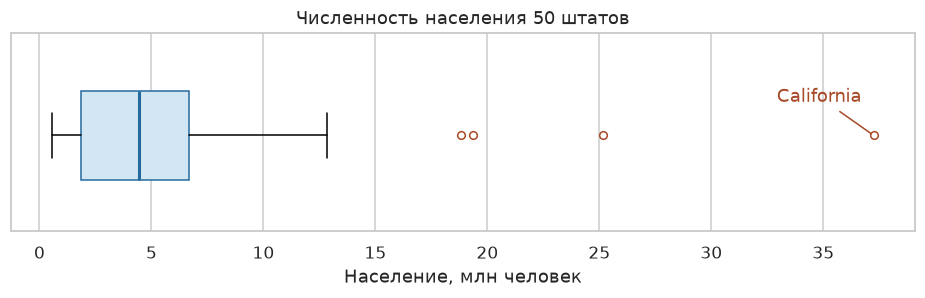

In [4]:
q1, q3 = population.quantile([0.25, 0.75])
iqr = q3 - q1
variation = pd.Series({
    "Выборочное стандартное отклонение": population.std(ddof=1),
    "Межквартильный размах": iqr,
    "MAD (масштабированный)": robust.scale.mad(population),
}, name="Население, чел.")
display(variation.to_frame())

low_fence = q1 - 1.5 * iqr
high_fence = q3 + 1.5 * iqr
flagged = state.loc[
    ~population.between(low_fence, high_fence), ["State", "Population"]
].sort_values("Population", ascending=False)
print(f"Верхняя граница по правилу 1,5 IQR: {high_fence / 1e6:.2f} млн чел.")
display(flagged.set_index("State"))

population_millions = population / 1e6
fig, ax = plt.subplots(figsize=(8.3, 2.6), layout="constrained")
ax.boxplot(
    population_millions, orientation="horizontal", whis=1.5, widths=0.42,
    patch_artist=True, boxprops={"facecolor": "#d2e7f3", "edgecolor": BLUE},
    medianprops={"color": BLUE, "linewidth": 2},
    flierprops={"marker": "o", "markeredgecolor": ORANGE, "markersize": 5},
)
max_index = population.idxmax()
ax.annotate(
    state.loc[max_index, "State"], xy=(population_millions.loc[max_index], 1),
    xytext=(-8, 22), textcoords="offset points", ha="right", color=ORANGE,
    arrowprops={"arrowstyle": "-", "color": ORANGE},
)
ax.set(title="Численность населения 50 штатов", xlabel="Население, млн человек", yticks=[])
ax.set_ylim(0.55, 1.48)
plt.show()

### Ответ 3

Стандартное отклонение составляет **6,848 млн**, IQR — **4,847 млн**, масштабированный MAD — **3,850 млн** человек. Стандартное отклонение чувствительно к крупным штатам из-за квадратов отклонений от среднего. IQR зависит от границ центральной половины наблюдений, MAD — от медианы абсолютных отклонений.

Верхняя граница по правилу 1,5 IQR равна **13,95 млн человек**. Её превышают California, Texas, New York и Florida. California с населением **37,25 млн** дальше всего от центральной группы. Правило отмечает редкие относительно остальных наблюдения. Для проверки ошибки потребовалось бы сопоставить значение с источником за тот же период.

## 4. Гистограммы и плотность

Для населения на вертикальной оси показано число штатов. Для уровня убийств гистограмма приведена к шкале плотности, чтобы её можно было сопоставить с ядерной оценкой плотности (KDE).

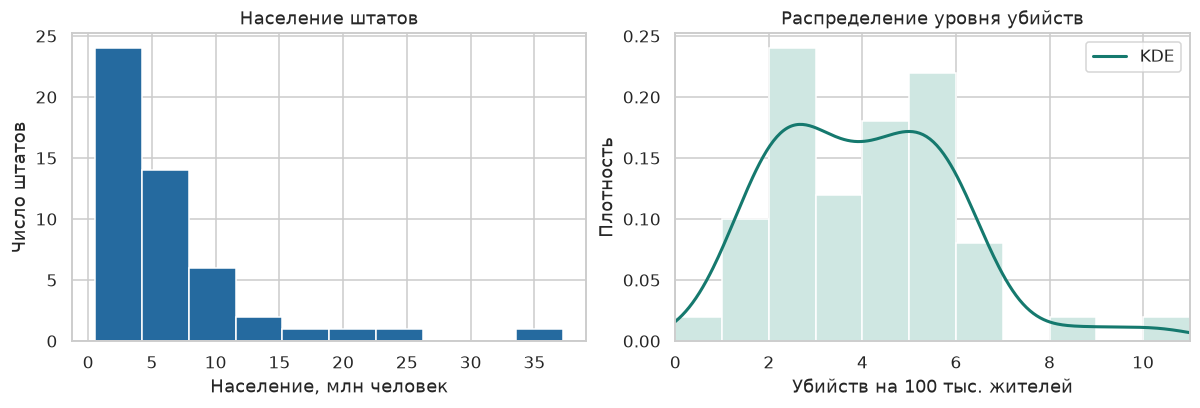

In [5]:
fig, (ax_pop, ax_rate) = plt.subplots(1, 2, figsize=(10.8, 3.6), layout="constrained")

ax_pop.hist(population_millions, bins=10, color=BLUE, edgecolor="white")
ax_pop.set(
    title="Население штатов",
    xlabel="Население, млн человек",
    ylabel="Число штатов",
)

rate_bins = np.arange(0, 12)
rate_grid = np.linspace(rate_bins[0], rate_bins[-1], 300)
rate_kde = gaussian_kde(murder_rate)
ax_rate.hist(murder_rate, bins=rate_bins, density=True, color="#cfe7e2", edgecolor="white")
ax_rate.plot(rate_grid, rate_kde(rate_grid), color=TEAL, linewidth=2, label="KDE")
ax_rate.set(
    title="Распределение уровня убийств",
    xlabel="Убийств на 100 тыс. жителей",
    ylabel="Плотность",
    xlim=(rate_bins[0], rate_bins[-1]),
)
ax_rate.legend()
plt.show()

### Ответ 4

Население выраженно асимметрично вправо. В первых двух интервалах гистограммы находятся 38 из 50 штатов, а справа виден длинный хвост. Уровень убийств распределён менее асимметрично. Большинство значений лежит между 2 и 6 на 100 тыс. жителей, отдельные значения достигают 7,9 и 10,3.

Boxplot быстро показывает медиану, квартильный размах и точки за усами. Гистограмма показывает заполненность отдельных интервалов. Слишком широкие интервалы скрывают локальные скопления, а слишком узкие подчёркивают случайные колебания частот. KDE сглаживает форму, степень сглаживания зависит от ширины ядра. Вероятность попадания в интервал оценивают по площади под кривой на этом интервале.

## 5. Категориальные данные, вероятности и ожидание

В `lc_loans` сравниваем статусы кредита внутри каждой категории `grade`. Деление на итог строки даёт эмпирическое условное распределение $P(\mathrm{status}\mid\mathrm{grade})$. Для 100 сопоставимых кредитов категории A ожидаемое число записей со статусом `Fully Paid` равно $100p$.

In [6]:
counts = pd.crosstab(lc_loans["grade"], lc_loans["status"])
row_shares = counts.div(counts.sum(axis=1), axis=0)

print("Число кредитов")
display(counts.assign(Всего=counts.sum(axis=1)))
print("Доля от числа кредитов данной категории, %")
display(row_shares.mul(100))

selected_grade = "A"
paid_status = "Fully Paid"
p_fully_paid = row_shares.loc[selected_grade, paid_status]
print(f"P(Fully Paid | grade={selected_grade}) = {p_fully_paid:.4f}")
print(f"Ожидаемое число из 100: {100 * p_fully_paid:.2f}")

Число кредитов


status,Charged Off,Current,Fully Paid,Late,Всего
grade,,,,,
A,1562,50051,20408,469,72490
B,5302,93852,31160,2056,132370
C,6023,88928,23147,2777,120875
D,5007,53281,13681,2308,74277
E,2842,24639,5949,1374,34804
F,1526,8444,2328,606,12904
G,409,1990,643,199,3241


Доля от числа кредитов данной категории, %


status,Charged Off,Current,Fully Paid,Late
grade,,,,
A,2.155,69.045,28.153,0.647
B,4.005,70.901,23.540,1.553
C,4.983,73.570,19.150,2.297
D,6.741,71.733,18.419,3.107
E,8.166,70.794,17.093,3.948
F,11.826,65.437,18.041,4.696
G,12.620,61.401,19.840,6.140


P(Fully Paid | grade=A) = 0.2815
Ожидаемое число из 100: 28.15


### Ответ 5

Среди **72 490** кредитов категории A статус `Fully Paid` имеют **20 408**, или **28,15%**. В модели для 100 сопоставимых независимых записей с той же вероятностью математическое ожидание равно **28,15 кредита**. Реальное число погашенных записей в новой группе может отличаться.

У **69,05%** кредитов категории A на момент выгрузки статус `Current`. Рассчитанная доля характеризует статус на дату наблюдения. Для оценки вероятности полного погашения к концу срока понадобились бы даты выдачи, сведения о сроках и дальнейшее наблюдение за этими кредитами.

## 6. Корреляции ETF и акции AT&T и Verizon

Берём значения с 1 июля 2012 года. Как в лекционном примере, используем готовые ряды дневных доходностей в шкале источника. Для ETF вычисляем матрицу Пирсона, для AT&T и Verizon сопоставляем значения одной даты.

Паспорт архива называет эти данные временными рядами цен, а лекция использует их как готовые доходности. В файле встречаются отрицательные значения. Расчёт сохраняет исходные значения, единица на осях обозначена как шкала источника.

Период: 02.07.2012 – 01.07.2015
ETF: 754 торговых дней, 17 тикеров.


,r Пирсона
SPY / DIA,0.954
SPY / VXX,-0.547
T / VZ,0.678


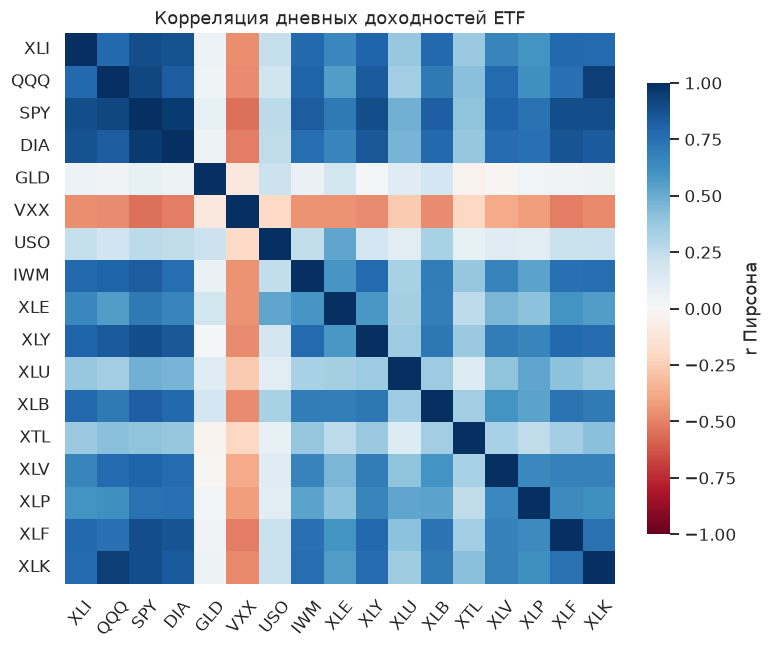

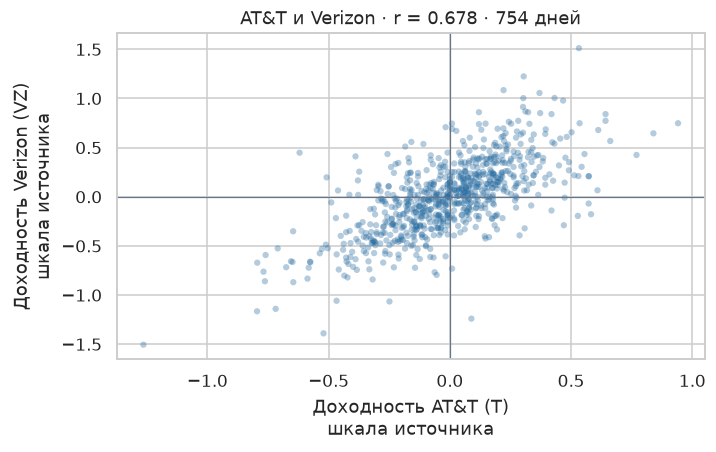

In [7]:
start = pd.Timestamp("2012-07-01")
etf_symbols = sectors.loc[sectors["sector"].eq("etf"), "symbol"].tolist()
etfs = sp500.loc[sp500.index >= start, etf_symbols]
telecom = sp500.loc[sp500.index >= start, ["T", "VZ"]].dropna()
etf_corr = etfs.corr(method="pearson")
telecom_corr = telecom["T"].corr(telecom["VZ"])

print(f"Период: {etfs.index.min():%d.%m.%Y} – {etfs.index.max():%d.%m.%Y}")
print(f"ETF: {len(etfs)} торговых дней, {etfs.shape[1]} тикеров.")
key_pairs = pd.Series({
    "SPY / DIA": etf_corr.loc["SPY", "DIA"],
    "SPY / VXX": etf_corr.loc["SPY", "VXX"],
    "T / VZ": telecom_corr,
}, name="r Пирсона")
display(key_pairs.to_frame())

fig, ax = plt.subplots(figsize=(7.2, 5.8), layout="constrained")
sns.heatmap(
    etf_corr, cmap="RdBu", vmin=-1, vmax=1, square=True, ax=ax,
    cbar_kws={"shrink": 0.82, "label": "r Пирсона"},
)
ax.set_title("Корреляция дневных доходностей ETF")
ax.tick_params(axis="x", labelrotation=50)
ax.tick_params(axis="y", labelrotation=0)
plt.show()

fig, ax = plt.subplots(figsize=(6.4, 4), layout="constrained")
ax.scatter(telecom["T"], telecom["VZ"], s=17, color=BLUE, alpha=0.35, edgecolors="none")
ax.axhline(0, color="#64748b", linewidth=0.8)
ax.axvline(0, color="#64748b", linewidth=0.8)
ax.set(
    title=f"AT&T и Verizon · r = {telecom_corr:.3f} · {len(telecom)} дней",
    xlabel="Доходность AT&T (T)\nшкала источника",
    ylabel="Доходность Verizon (VZ)\nшкала источника",
)
plt.show()

### Ответ 6

С 2 июля 2012 года по 1 июля 2015 года у SPY и DIA наблюдается сильная положительная линейная связь ($r=0{,}954$). У SPY и VXX связь отрицательная ($r=-0{,}547$). На диаграмме AT&T и Verizon облако наклонено вверх, что согласуется с $r=0{,}678$ по 754 торговым дням.

Коэффициент Пирсона описывает линейную связь на данном отрезке. Общие рыночные факторы могут двигать обе бумаги в одну сторону. Несколько необычных торговых дней могут существенно повлиять на коэффициент, а смена рыночного периода — изменить его.

## 7. Связи между несколькими переменными

Для данных жилья в округе Кинг берём объекты площадью свыше 100 и менее 3 500 кв. футов с налоговой оценкой ниже 750 000 долларов. На hexbin цвет показывает число объектов в ячейке. Контуры KDE рассчитаны на случайной подвыборке из 10 000 объектов с фиксированным зерном.

После отбора: 432,693 из 498,249 записей, r = 0.531


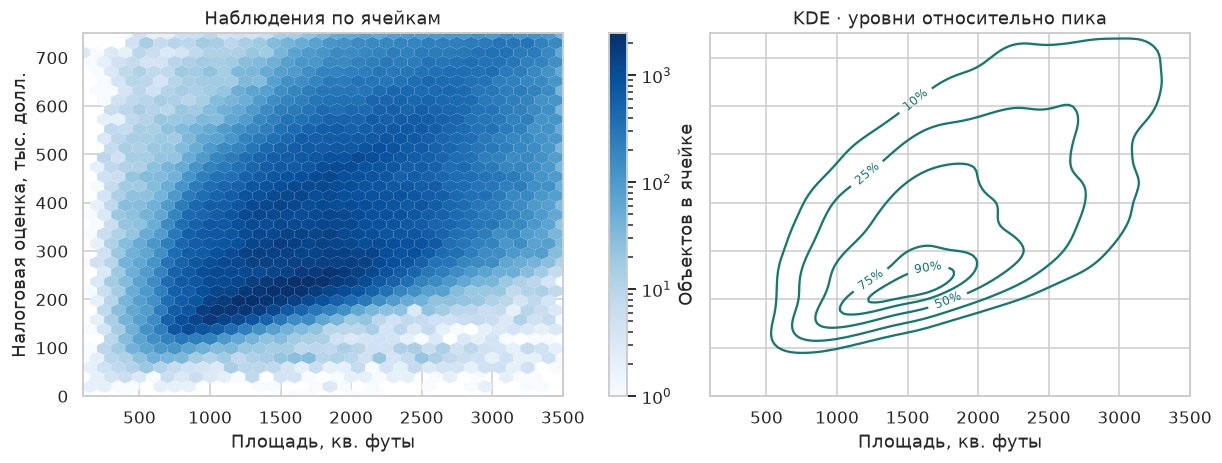

In [8]:
area = "SqFtTotLiving"
value = "TaxAssessedValue"
housing = kc_tax.loc[
    kc_tax[area].gt(100) & kc_tax[area].lt(3_500) & kc_tax[value].lt(750_000)
].copy()
housing["value_thousands"] = housing[value] / 1_000
value_k = "value_thousands"
extent = (100, 3_500, 0, 750)
housing_corr = housing[area].corr(housing[value])
print(f"После отбора: {len(housing):,} из {len(kc_tax):,} записей, r = {housing_corr:.3f}")

sample = housing.sample(n=10_000, random_state=42)
housing_kde = gaussian_kde(sample[[area, value_k]].to_numpy().T)
x_grid, y_grid = np.meshgrid(
    np.linspace(extent[0], extent[1], 120),
    np.linspace(extent[2], extent[3], 120),
)
density = housing_kde(np.vstack([x_grid.ravel(), y_grid.ravel()])).reshape(x_grid.shape)

fig, (ax_hex, ax_kde) = plt.subplots(
    1, 2, figsize=(11, 4.1), sharex=True, sharey=True, layout="constrained"
)
hexes = ax_hex.hexbin(
    housing[area], housing[value_k], gridsize=34, extent=extent,
    mincnt=1, cmap="Blues", norm=LogNorm(), linewidths=0,
)
fig.colorbar(hexes, ax=ax_hex, label="Объектов в ячейке")
ax_hex.set_title("Наблюдения по ячейкам")

contours = ax_kde.contour(
    x_grid, y_grid, density / density.max(),
    levels=[0.1, 0.25, 0.5, 0.75, 0.9], colors=TEAL,
)
ax_kde.clabel(contours, fmt=lambda level: f"{level:.0%}", fontsize=8)
ax_kde.set_title("KDE · уровни относительно пика")
ax_hex.set_ylabel("Налоговая оценка, тыс. долл.")
for ax in (ax_hex, ax_kde):
    ax.set(xlabel="Площадь, кв. футы", xlim=extent[:2], ylim=extent[2:])
plt.show()

В `airline_stats` сравниваем долю прибывших рейсов с задержкой по причинам перевозчика (`pct_carrier_delay`). Записи с пропуском этой доли исключаем. Для обеих панелей шкала линейна до 10%, дальше логарифмическая. [Подготовка данных об авиарейсах](https://github.com/andrewgbruce/statistics-for-data-scientists/blob/master/src/prep_datasets.r).

,Записей,"Медиана, %"
airline,,
Alaska,3851,3.226
Delta,9095,5.548
United,5414,6.445
Southwest,5584,6.961
Jet Blue,3773,7.658
American,5723,8.429


Исключено строк с пропусками: 28


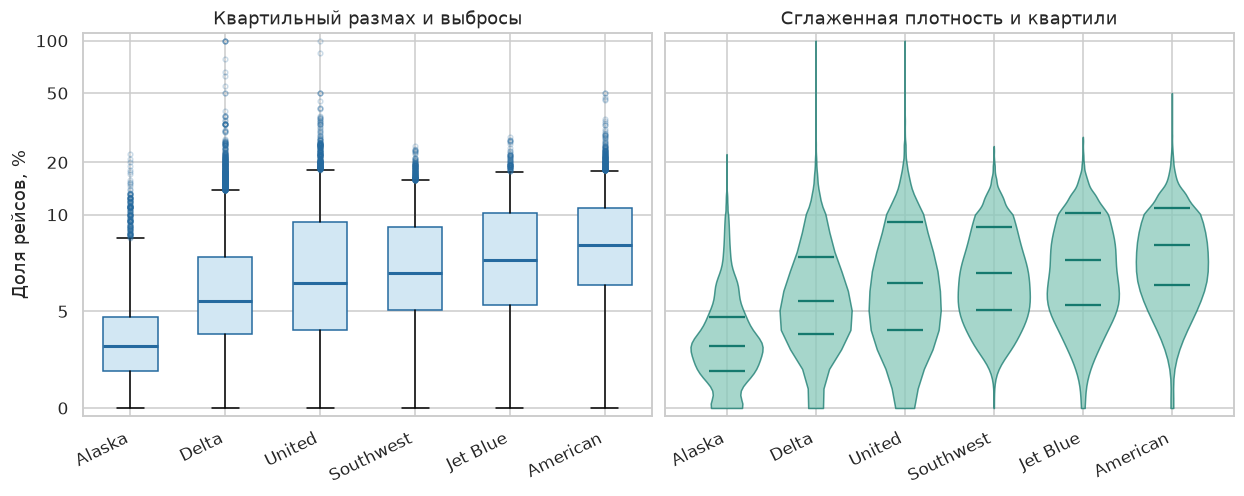

In [9]:
delay = "pct_carrier_delay"
delays = airline_stats.dropna(subset=[delay])
airline_summary = delays.groupby("airline")[delay].agg(["size", "median"])
airline_summary = airline_summary.sort_values("median")
display(airline_summary.rename(columns={"size": "Записей", "median": "Медиана, %"}))
print(f"Исключено строк с пропусками: {len(airline_stats) - len(delays)}")

airlines = airline_summary.index.tolist()
series = [delays.loc[delays["airline"].eq(airline), delay] for airline in airlines]
positions = np.arange(len(airlines))
fig, (ax_box, ax_violin) = plt.subplots(
    1, 2, figsize=(11.2, 4.4), sharey=True, layout="constrained"
)
ax_box.boxplot(
    series, positions=positions, widths=0.57, patch_artist=True,
    boxprops={"facecolor": "#d2e7f3", "edgecolor": BLUE},
    medianprops={"color": BLUE, "linewidth": 2},
    flierprops={"marker": ".", "markeredgecolor": BLUE, "alpha": 0.23},
)
violins = ax_violin.violinplot(
    series, positions=positions, widths=0.81, showextrema=False,
    quantiles=[[0.25, 0.50, 0.75]] * len(airlines),
)
for body in violins["bodies"]:
    body.set(facecolor="#88c9ba", edgecolor=TEAL, alpha=0.75)
violins["cquantiles"].set_color(TEAL)
ax_box.set(title="Квартильный размах и выбросы", ylabel="Доля рейсов, %")
ax_violin.set_title("Сглаженная плотность и квартили")
for ax in (ax_box, ax_violin):
    ax.set_xticks(positions, airlines, rotation=26, ha="right")
    ax.set_yscale("symlog", linthresh=10)
    ax.set_yticks([0, 5, 10, 20, 50, 100], ["0", "5", "10", "20", "50", "100"])
    ax.set_ylim(-0.4, 110)
plt.show()

Сравним четыре почтовых индекса на одинаковых осях и с общей цветовой шкалой. Помимо медиан по каждой группе сравним оценки жилья в узком диапазоне 1 450–1 550 кв. футов.

,Объектов,"Медиана площади, кв. футы","Медиана оценки, долл.",Объектов в диапазоне,"Медиана оценки в диапазоне, долл."
ZipCode,,,,,
98105,4481,"1,690.000","537,000.000",332,"510,000.000"
98108,5535,"1,530.000","271,000.000",385,"273,000.000"
98126,5631,"1,370.000","328,000.000",367,"345,000.000"
98188,4043,"1,560.000","210,000.000",254,"204,000.000"


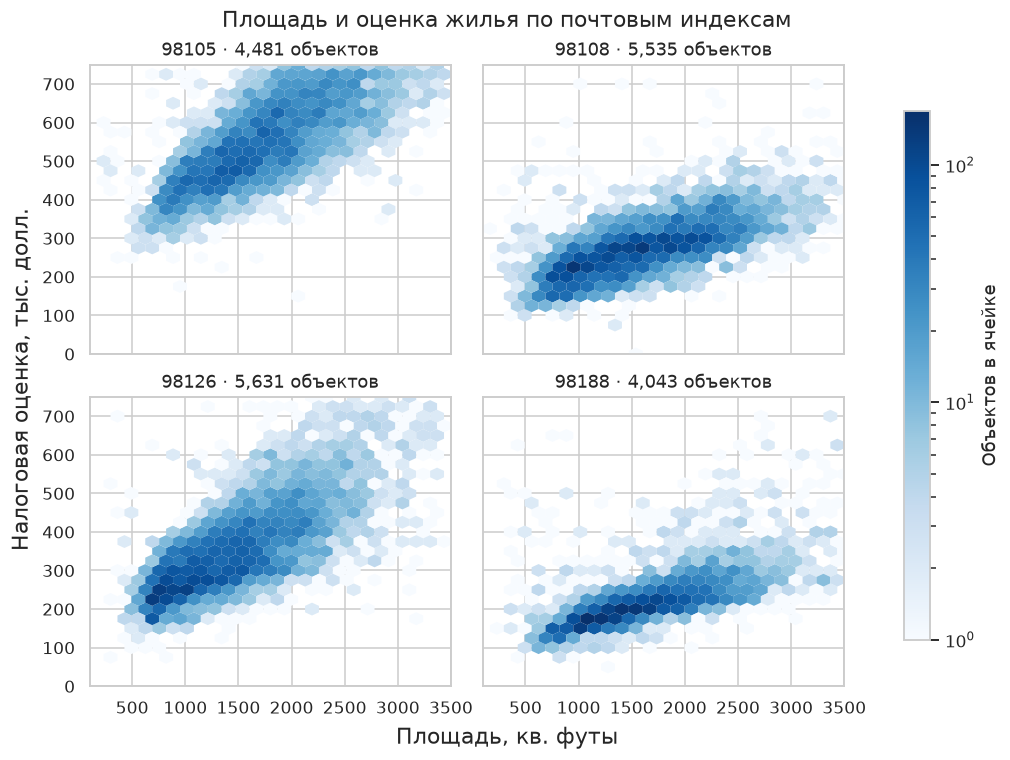

In [10]:
zip_codes = ["98105", "98108", "98126", "98188"]
housing_by_zip = housing.loc[housing["ZipCode"].isin(zip_codes)]
median_by_zip = housing_by_zip.groupby("ZipCode").agg(
    n=(value, "size"), median_area=(area, "median"), median_value=(value, "median"),
)
similar_area = housing_by_zip.loc[housing_by_zip[area].between(1_450, 1_550)]
median_similar_area = similar_area.groupby("ZipCode").agg(
    n_similar=(value, "size"), median_value_similar=(value, "median"),
)
display(median_by_zip.join(median_similar_area).rename(columns={
    "n": "Объектов",
    "median_area": "Медиана площади, кв. футы",
    "median_value": "Медиана оценки, долл.",
    "n_similar": "Объектов в диапазоне",
    "median_value_similar": "Медиана оценки в диапазоне, долл.",
}))

fig, axes = plt.subplots(
    2, 2, figsize=(9.1, 6.8), sharex=True, sharey=True, layout="constrained"
)
hex_collections = []
for zipcode, ax in zip(zip_codes, axes.flat):
    objects = housing_by_zip.loc[housing_by_zip["ZipCode"].eq(zipcode)]
    hexes = ax.hexbin(
        objects[area], objects[value_k], gridsize=26, extent=extent,
        mincnt=1, cmap="Blues", linewidths=0,
    )
    hex_collections.append(hexes)
    ax.set(title=f"{zipcode} · {len(objects):,} объектов", xlim=extent[:2], ylim=extent[2:])

max_count = max(hexes.get_array().max() for hexes in hex_collections)
shared_norm = LogNorm(vmin=1, vmax=max_count)
for hexes in hex_collections:
    hexes.set_norm(shared_norm)

fig.suptitle("Площадь и оценка жилья по почтовым индексам")
fig.supxlabel("Площадь, кв. футы")
fig.supylabel("Налоговая оценка, тыс. долл.")
fig.colorbar(hex_collections[0], ax=axes, shrink=0.85, label="Объектов в ячейке")
plt.show()

### Ответ 7

- **Площадь и стоимость.** Среди 432 693 объектов после фильтрации площадь и налоговая оценка связаны положительно ($r=0{,}531$). При большей площади цены в целом выше, а при близких площадях заметен широкий разброс. Hexbin использует все наблюдения и показывает число объектов в ячейке. Контуры KDE выделяют область максимальной плотности, но зависят от подвыборки и сглаживания у границ фильтра.
- **Задержки.** Медиана доли рейсов, задержанных по причинам перевозчика, составляет **3,23%** у Alaska и **8,43%** у American. Boxplot выделяет квартили и редкие высокие наблюдения. Violin plot показывает, где сосредоточены значения. Медианы вычислены по записям с равными весами. Для расчёта сводной доли по всем рейсам потребовалось бы число рейсов в каждой записи.
- **Почтовые индексы.** Медиана налоговой оценки для 98105 равна **537 тыс. долл.**, для 98188 — **210 тыс. долл.** В диапазоне 1 450–1 550 кв. футов медианы этих групп составляют **510** и **204 тыс. долл.** соответственно. Фасеты показывают, где сосредоточены наблюдения в каждом индексе. Общая шкала цвета сравнивает абсолютные количества, поэтому её нужно читать с учётом размеров групп.

Асимметрия населения, доли кредитных статусов и медианы задержек описывают данные. Корреляции доходностей и различия оценок жилья по индексам характеризуют статистические связи. Для оценки причинного эффекта площади или местоположения на стоимость понадобились бы дополнительные характеристики объектов, например состояние и год постройки, и дизайн сравнения, учитывающий их влияние.

В архиве `data-EDA.zip` сохранены паспорт с контрольными суммами и лицензия набора. [Исходный репозиторий данных](https://github.com/gedeck/practical-statistics-for-data-scientists/tree/master/data).